# Customer Engagement & Product Utilization Analytics for Retention Strategy

European bank dataset, 10,000 customers. Run from the project folder so `analysis.py` and `data/` are found.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import analysis as a

pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (7, 3.8), 'axes.spines.top': False, 'axes.spines.right': False})
raw = a.load_data()
raw.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 1. Data ingestion and validation

In [2]:
raw.info()
print(a.validate(raw))
raw.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB
{'rows': 10000, 'columns': 14, 'missing_values': 0, 'duplicate_rows': 0, 'duplicate_customer_ids': 0, 'binary

,count,mean,std,min,25%,50%,75%,max
Year,10000.0,2.025000e+03,0.000000,2025.00,2025.00,2.025000e+03,2.025000e+03,2025.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


Findings: no missing values, no duplicates, binary columns valid, churn rate 20.37%. `Surname` and `Year` are not used in the analysis.

In [3]:
df = a.prepare(raw)
df[['Engagement_Profile','HighBalance','RSI','RSI_Tier','BalanceBand','AtRiskPremium']].head()

,Engagement_Profile,HighBalance,RSI,RSI_Tier,BalanceBand,AtRiskPremium
0,Active but low-product,False,69.0,Strong,Zero,False
1,Active but low-product,False,67.0,Strong,Mid (80-120k),False
2,Inactive high-balance,True,46.0,Moderate,High (>120k),False
3,Inactive disengaged,False,32.0,Moderate,Zero,False
4,Active but low-product,True,69.0,Strong,High (>120k),False


## 1b. Exploratory data analysis

In [4]:
num = ['CreditScore','Age','Tenure','Balance','EstimatedSalary','NumOfProducts']
summ = df[num].describe().T[['mean','50%','std','min','max']].round(1)
summ['skew'] = df[num].skew().round(2)
summ

,mean,50%,std,min,max,skew
CreditScore,650.5,652.0,96.7,350.0,850.0,-0.07
Age,38.9,37.0,10.5,18.0,92.0,1.01
Tenure,5.0,5.0,2.9,0.0,10.0,0.01
Balance,76485.9,97198.5,62397.4,0.0,250898.1,-0.14
EstimatedSalary,100090.2,100193.9,57510.5,11.6,199992.5,0.00
NumOfProducts,1.5,1.0,0.6,1.0,4.0,0.75


In [5]:
# Outliers (IQR rule) and the zero-balance group
for c in ['CreditScore','Age','Balance','EstimatedSalary']:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    print(c, 'outliers:', int(((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()))
print('Zero balance:', (df.Balance == 0).sum(), f'({(df.Balance == 0).mean():.1%})')
df[df.Balance > 0].Balance.describe().round(0)

CreditScore outliers: 15
Age outliers: 359
Balance outliers: 0
EstimatedSalary outliers: 0
Zero balance: 3617 (36.2%)


count      6383.0
mean     119827.0
std       30095.0
min        3769.0
25%      100182.0
50%      119840.0
75%      139512.0
max      250898.0
Name: Balance, dtype: float64

In [6]:
for c in ['Geography','Gender','NumOfProducts','HasCrCard','IsActiveMember','Exited']:
    print((df[c].value_counts(normalize=True)*100).round(1).to_dict())

{'France': 50.1, 'Germany': 25.1, 'Spain': 24.8}
{'Male': 54.6, 'Female': 45.4}
{1: 50.8, 2: 45.9, 3: 2.7, 4: 0.6}
{1: 70.6, 0: 29.4}
{1: 51.5, 0: 48.5}
{0: 79.6, 1: 20.4}


In [7]:
# Correlation with churn (linear only; product count is non-linear, see section 3)
df[num + ['HasCrCard','IsActiveMember','Exited']].corr()['Exited'].round(3).sort_values()

IsActiveMember    -0.156
NumOfProducts     -0.048
CreditScore       -0.027
Tenure            -0.014
HasCrCard         -0.007
EstimatedSalary    0.012
Balance            0.119
Age                0.285
Exited             1.000
Name: Exited, dtype: float64

                  count   mean
Geography Funded              
France    False    2418  0.139
          True     2596  0.182
Germany   True     2509  0.324
Spain     False    1199  0.136
          True     1278  0.196
     AgeBand  customers  churned  churn_rate
0    (0, 30]       1968      148        7.52
1   (30, 40]       4451      538       12.09
2   (40, 50]       2320      788       33.97
3   (50, 60]        797      448       56.21
4  (60, 100]        464      115       24.78


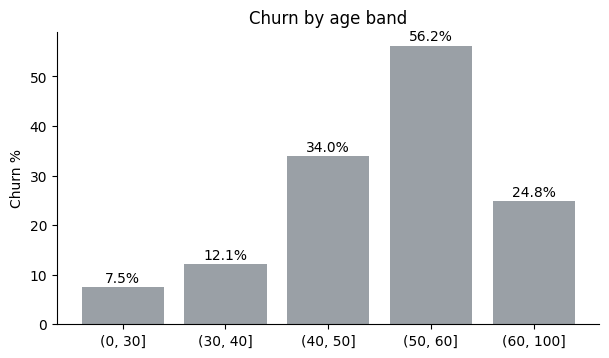

In [8]:
# Country and balance are entangled: Germany has no zero-balance customers
df['Funded'] = df.Balance > 0
print(df.groupby(['Geography','Funded']).Exited.agg(['count','mean']).round(3))
age = a.churn_by(df.assign(AgeBand=pd.cut(df.Age,[0,30,40,50,60,100])), 'AgeBand'); print(age)
fig, ax = plt.subplots(); ax.bar(age.AgeBand.astype(str), age.churn_rate, color='#9aa0a6')
for k, v in enumerate(age.churn_rate): ax.text(k, v+1, f'{v:.1f}%', ha='center')
ax.set_ylabel('Churn %'); ax.set_title('Churn by age band'); plt.show()

## 2. Engagement classification

Priority order: Inactive high-balance, Active engaged, Active but low-product, Inactive disengaged. High balance = top half of non-zero balances.

       Engagement_Profile  customers  churned  churn_rate
1          Active engaged       2588      250        9.66
0  Active but low-product       2563      485       18.92
2     Inactive disengaged       3280      812       24.76
3   Inactive high-balance       1569      490       31.23
     Status  customers  churned  churn_rate
0    Active       5151      735       14.27
1  Inactive       4849     1302       26.85


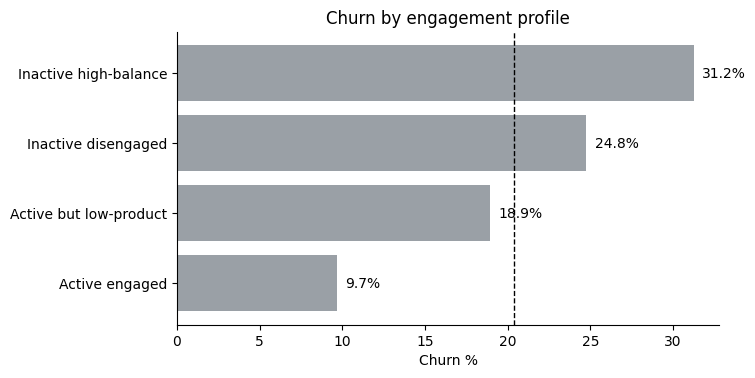

In [9]:
prof = a.churn_by(df, 'Engagement_Profile').sort_values('churn_rate')
print(prof)
act = a.churn_by(df.assign(Status=df.IsActiveMember.map({1:'Active',0:'Inactive'})), 'Status')
print(act)
fig, ax = plt.subplots()
ax.barh(prof.Engagement_Profile, prof.churn_rate, color='#9aa0a6')
ax.axvline(df.Exited.mean()*100, ls='--', c='k', lw=1)
for i, v in enumerate(prof.churn_rate): ax.text(v+0.5, i, f'{v:.1f}%', va='center')
ax.set_xlabel('Churn %'); ax.set_title('Churn by engagement profile'); plt.show()

## 3. Product utilization analysis

   NumOfProducts  customers  churned  churn_rate
0              1       5084     1409       27.71
1              2       4590      348        7.58
2              3        266      220       82.71
3              4         60       60      100.00


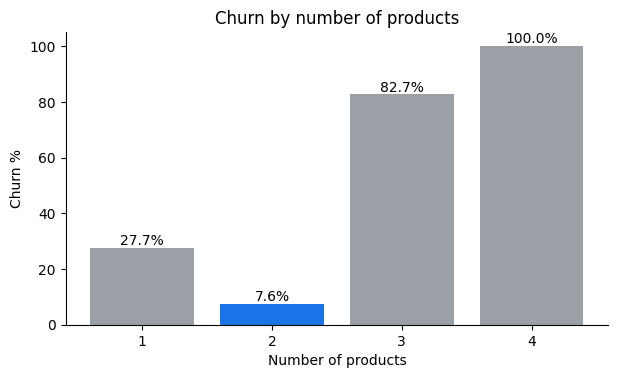

NumOfProducts      1    2     3      4
IsActiveMember                        
0               36.7  9.9  88.2  100.0
1               18.9  5.6  75.2  100.0
3-4 products: {'sum': 280.0, 'count': 326.0, 'mean': 0.8588957055214724}


In [10]:
p = a.churn_by(df, 'NumOfProducts'); print(p)
fig, ax = plt.subplots()
ax.bar(p.NumOfProducts.astype(str), p.churn_rate, color=['#9aa0a6','#1a73e8','#9aa0a6','#9aa0a6'])
for i, v in enumerate(p.churn_rate): ax.text(i, v+1, f'{v:.1f}%', ha='center')
ax.set_xlabel('Number of products'); ax.set_ylabel('Churn %'); ax.set_title('Churn by number of products'); plt.show()
heat = df.pivot_table(index='IsActiveMember', columns='NumOfProducts', values='Exited', aggfunc='mean').mul(100).round(1)
print(heat)
print('3-4 products:', df[df.NumOfProducts>=3].Exited.agg(['sum','count','mean']).to_dict())

Two products is the retention sweet spot (7.6% churn). Three or four products churn at 86% combined, even among active members.

## 4. Financial commitment vs engagement

In [11]:
print(a.churn_by(df, 'BalanceBand'))
print(df.assign(Status=df.IsActiveMember.map({1:'Active',0:'Inactive'})).groupby(['Status','HighBalance']).Exited.agg(['count','mean']).round(3))
risk = df[df.AtRiskPremium]
print('At-risk premium:', len(risk), 'churn', round(risk.Exited.mean()*100,1), '%')
print('Still with bank:', (risk.Exited==0).sum(), 'balance', round(risk[risk.Exited==0].Balance.sum()/1e6,1), 'M')
mm = df[df.Salary_Balance_Mismatch]
print('Salary-balance mismatch:', len(mm), 'churn', round(mm.Exited.mean()*100,1), '%')

     BalanceBand  customers  churned  churn_rate
0           Zero       3617      500       13.82
1     Low (<80k)        585      129       22.05
2  Mid (80-120k)       2617      643       24.57
3   High (>120k)       3181      765       24.05
                      count   mean
Status   HighBalance              
Active   False         3528  0.128
         True          1623  0.174
Inactive False         3280  0.248
         True          1569  0.312
At-risk premium: 1054 churn 34.3 %
Still with bank: 693 balance 99.2 M
Salary-balance mismatch: 1777 churn 14.3 %


## 5. Retention strength assessment

In [12]:
print(a.churn_by(df, 'RSI_Tier'))
print(df.groupby('Exited').RSI.mean().round(1))
print(a.churn_by(df, 'Tenure')[['Tenure','churn_rate']].T)

      RSI_Tier  customers  churned  churn_rate
0         Weak       1359      510       37.53
1     Moderate       3490      792       22.69
2       Strong       1452      290       19.97
3  Very strong       3699      445       12.03
Exited
0    60.9
1    47.5
Name: RSI, dtype: float64
              0      1      2      3      4      5      6      7      8      9      10
Tenure       0.0   1.00   2.00   3.00   4.00   5.00   6.00   7.00   8.00   9.00  10.00
churn_rate  23.0  22.42  19.18  21.11  20.53  20.65  20.27  17.22  19.22  21.65  20.61


## 6. KPIs

In [13]:
pd.DataFrame(a.kpis(df).items(), columns=['KPI','Value'])

,KPI,Value
0,Engagement Retention Ratio,1.88
1,"Product Depth Index (2 vs 1 product, retention...",20.10
2,High-Balance Disengagement Rate (%),49.20
3,High-Balance Disengaged Churn Rate (%),31.20
4,"Credit Card Stickiness Score (pp gap, no-card ...",0.63
5,"Relationship Strength Index (avg, retained)",60.90
6,"Relationship Strength Index (avg, churned)",47.50


## 7. Demographic context and model check

Do behavioural variables explain churn better than demographics? Compare logistic regressions by AUC.

In [14]:
print(a.churn_by(df, 'Geography')); print(a.churn_by(df, 'Gender'))
print(a.churn_by(df.assign(AgeBand=pd.cut(df.Age,[0,30,40,50,60,100])), 'AgeBand'))

  Geography  customers  churned  churn_rate
0    France       5014      810       16.15
1   Germany       2509      814       32.44
2     Spain       2477      413       16.67
   Gender  customers  churned  churn_rate
0  Female       4543     1139       25.07
1    Male       5457      898       16.46
     AgeBand  customers  churned  churn_rate
0    (0, 30]       1968      148        7.52
1   (30, 40]       4451      538       12.09
2   (40, 50]       2320      788       33.97
3   (50, 60]        797      448       56.21
4  (60, 100]        464      115       24.78


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

demo = pd.get_dummies(df[['Geography','Gender','Age','CreditScore']], drop_first=True)
beh = df[['IsActiveMember','NumOfProducts','HasCrCard','Tenure','Balance','EstimatedSalary']].copy()
beh['P2'] = (beh.NumOfProducts == 2).astype(int); beh['P34'] = (beh.NumOfProducts >= 3).astype(int)
res = {}
for name, X in [('Demographics only', demo), ('Behaviour only', beh), ('Combined', pd.concat([demo, beh], axis=1))]:
    Xtr, Xte, ytr, yte = train_test_split(X, df.Exited, test_size=.25, random_state=42, stratify=df.Exited)
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    res[name] = round(roc_auc_score(yte, m.predict_proba(Xte)[:,1]), 3)
pd.Series(res, name='AUC')

Demographics only    0.755
Behaviour only       0.754
Combined             0.847
Name: AUC, dtype: float64

Behaviour alone (0.754) is about as predictive as demographics alone (0.755); combined reaches 0.847. Segment by both.

## 8. Export the at-risk watch-list

In [16]:
wl = df[df.AtRiskPremium & (df.Exited==0)][['CustomerId','Surname','Geography','Age','Tenure','Balance','EstimatedSalary','RSI']].sort_values('Balance', ascending=False)
wl.to_csv('at_risk_premium.csv', index=False)
print(len(wl)); wl.head()

693


,CustomerId,Surname,Geography,Age,Tenure,Balance,EstimatedSalary,RSI
3588,15571958,McIntosh,Spain,40,3,221532.80,171867.08,21.0
3920,15620268,Thomson,Germany,43,3,212696.32,115268.86,21.0
2709,15780212,Mao,France,37,4,212692.97,176395.02,23.0
8982,15627971,Coates,France,32,8,206663.75,16281.94,31.0
4436,15664498,Golovanov,France,26,7,205962.00,156424.40,29.0


## Conclusions

1. Inactive customers churn at 26.9% vs 14.3% for active.
2. Two products retain best; three or four products are a red flag.
3. High balance does not ensure loyalty; inactive high-balance customers are the risk group.
4. Behaviour and demographics are equally predictive alone and much stronger together.